# Retail Sales Analysis and Prediction Using Python

## Project Overview
This project analyzes retail sales data to identify sales trends, customer purchasing patterns, and product performance using Python.

## Objectives
- Clean and prepare the retail dataset.
- Perform Exploratory Data Analysis (EDA).
- Visualize sales trends and product performance.
- Identify actionable business insights.
- Build and evaluate a machine learning model if the dataset supports a meaningful prediction task.

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.

## Expected Outcome
Generate data-driven insights that can help businesses understand sales performance and make better decisions.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Retail Analytics libraries imported successfully!")

Retail Analytics libraries imported successfully!


In [3]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx'

df_transactions = pd.read_excel(url, sheet_name='Year 2010-2011')
df_transactions['InvoiceDate'] = pd.to_datetime(df_transactions['InvoiceDate'])

print("Dataset shape:", df_transactions.shape)
display(df_transactions.head())

Dataset shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
# Load the retail dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"

df = pd.read_excel(url, sheet_name="Year 2010-2011")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Understand the dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[us]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing Values:
Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Duplicate Rows: 5268

Statistical Summary:


,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


In [8]:

# Load the retail dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"

df = pd.read_excel(url, sheet_name="Year 2010-2011")

print("Dataset shape:", df.shape)
display(df.head())

# Understand the dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[us]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing Values:
Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Duplicate Rows: 5268

Statistical Summary:


,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


In [9]:

# Step 2: Data Cleaning

df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# Exclude cancelled invoices
df_clean["Invoice"] = df_clean["Invoice"].astype(str)
df_clean = df_clean[~df_clean["Invoice"].str.startswith("C")]

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

# Calculate revenue
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing customer IDs:", df_clean["Customer ID"].isna().sum())
print("Total Revenue (£):", round(df_clean["Revenue"].sum(), 2))
print("Remaining duplicates:", df_clean.duplicated().sum())

Original rows: 541910
Cleaned rows: 524879
Missing customer IDs: 132186
Total Revenue (£): 10642128.8
Remaining duplicates: 0


In [10]:

# Step 3: Key Performance Indicators (KPIs)

total_revenue = df_clean["Revenue"].sum()
total_orders = df_clean["Invoice"].nunique()
total_customers = df_clean["Customer ID"].nunique()
total_products = df_clean["StockCode"].nunique()
average_order_value = total_revenue / total_orders

print("===== RETAIL SALES KPI REPORT =====")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

===== RETAIL SALES KPI REPORT =====
Total Revenue: £10,642,128.80
Total Orders: 19,960
Unique Customers: 4,338
Unique Products: 3,922
Average Order Value: £533.17


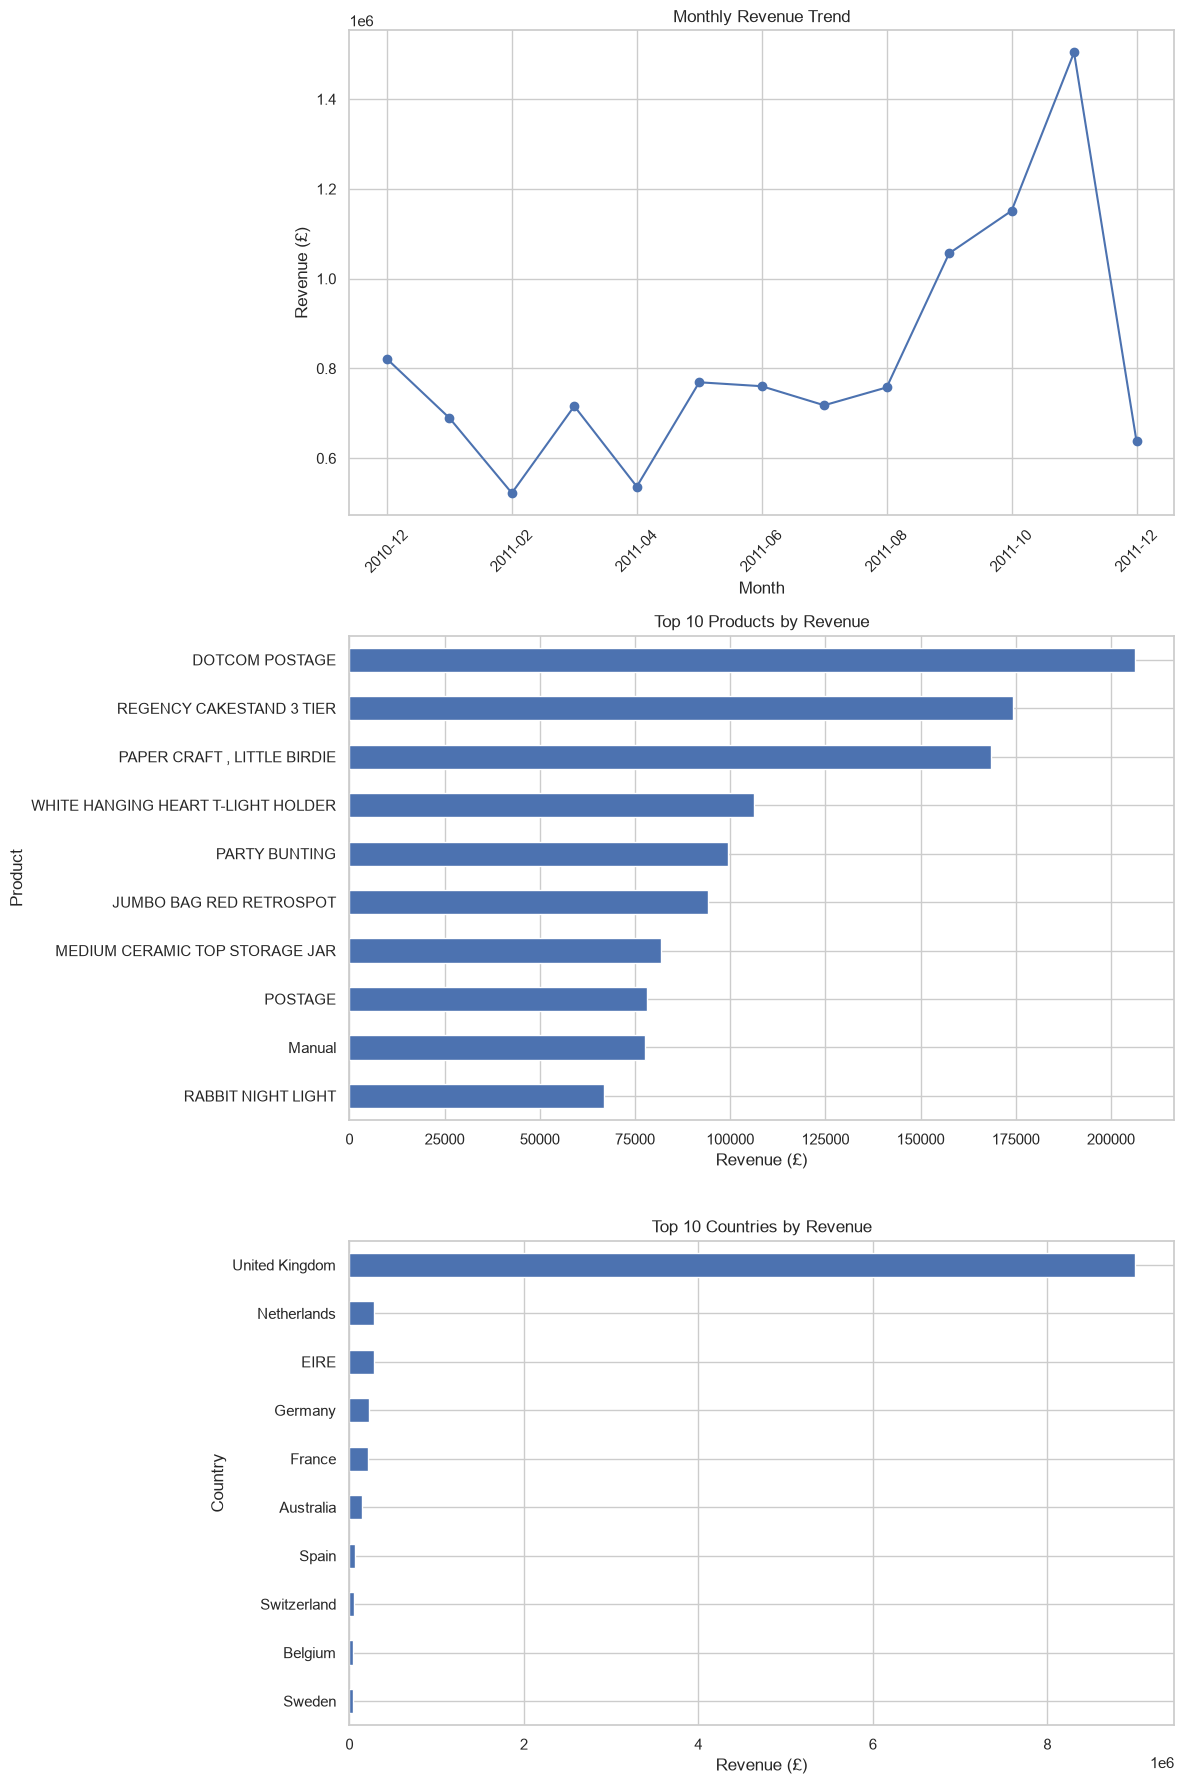

In [12]:

# Step 4: Retail Sales Visualizations

# Prepare data for charts
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

monthly_revenue = df_clean.groupby("Month")["Revenue"].sum()
top_products = df_clean.groupby("Description")["Revenue"].sum().nlargest(10)
top_countries = df_clean.groupby("Country")["Revenue"].sum().nlargest(10)

# Create three charts
fig, axes = plt.subplots(3, 1, figsize=(12, 18))

# Chart 1: Monthly Revenue
monthly_revenue.plot(
    kind="line", marker="o", ax=axes[0]
)
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (£)")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Top 10 Products
top_products.sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 10 Products by Revenue")
axes[1].set_xlabel("Revenue (£)")
axes[1].set_ylabel("Product")

# Chart 3: Top 10 Countries
top_countries.sort_values().plot(
    kind="barh", ax=axes[2]
)
axes[2].set_title("Top 10 Countries by Revenue")
axes[2].set_xlabel("Revenue (£)")
axes[2].set_ylabel("Country")

plt.tight_layout()
plt.show()


# Step 5: Business Insights and Conclusions

## Key Findings
- The cleaned retail dataset contains **524,879 transaction records**.
- Total revenue from the cleaned transactions is **£10,642,128.80**.
- The dataset contains **19,960 unique invoices**, representing orders.
- A total of **4,338 unique customers** and **3,922 unique products** were identified.
- The average revenue per invoice is **£533.17**.
- Monthly revenue trends help identify seasonal patterns and high-performing sales periods.
- Product and country revenue comparisons highlight important products and major markets.

## Business Recommendations
1. **Improve inventory planning:** Use monthly sales trends to plan stock levels during high-demand periods.
2. **Focus on top-performing products:** Maintain sufficient stock of products generating the highest revenue.
3. **Strengthen major markets:** Prioritize customer retention and marketing in countries contributing the most revenue.
4. **Increase customer retention:** Use loyalty programs and targeted offers to encourage repeat purchases.
5. **Improve data quality:** Investigate missing customer IDs and monitor cancelled transactions to improve reporting accuracy.

## Conclusion
This project demonstrates an end-to-end retail sales analysis workflow using Python, Pandas, Matplotlib, and Seaborn. The transaction data was cleaned, key performance indicators were calculated, and visualizations were created to explore monthly revenue trends, top-performing products, and country-level sales. These findings can support data-driven decisions related to inventory, marketing, and customer retention.

## Dataset and Limitations
**Dataset:** UCI Online Retail II — Year 2010–2011 sheet.

The analysis excludes duplicate records, cancelled invoices, missing product descriptions, and transactions with non-positive quantities or prices. Customer IDs are not required for every sales calculation, so transactions with missing customer IDs were retained. The findings represent historical data and may not reflect current retail conditions.